<a href="https://colab.research.google.com/github/riveranelizabeth-ship-it/Actividad-4/blob/main/SentimentAI_Banking_Actividad4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SentimentAI Banking · Actividad 4
Comparación de tres modelos de Hugging Face para clasificar comentarios bancarios en español.

## 1. Caso de uso y selección
El prototipo identifica satisfacción, ausencia de valoración e insatisfacción en comentarios sobre diez servicios bancarios. Es una ayuda para explorar experiencias; una predicción negativa no identifica por sí sola fraude ni una reclamación jurídicamente procedente.

| Nombre | Identificador de Hugging Face | Justificación |
|---|---|---|
| BETO | `finiteautomata/beto-sentiment-analysis` | BERT en español ajustado a TASS 2020; referencia monolingüe. |
| RoBERTuito | `pysentimiento/robertuito-sentiment-analysis` | RoBERTa para texto social en español, ajustado a TASS 2020. |
| XLM-RoBERTa | `cardiffnlp/twitter-xlm-roberta-base-sentiment` | Modelo multilingüe ajustado a sentimientos en ocho idiomas, incluido español. |

Los tres clasifican en positivo, neutral y negativo. No se incluye una versión genérica de DistilBERT sin ajuste para esta tarea. Se comparan **checkpoints completos**: las diferencias no pueden atribuirse solo a la arquitectura, pues cambian también sus datos y procesos de entrenamiento.

**Disponibilidad:** la ficha de BETO anuncia un futuro retiro y recomienda RoBERTuito. Se registra la revisión de cada modelo; si deja de estar disponible, el experimento debe detenerse y documentar una nueva selección, sin reemplazarlo silenciosamente.

**Hugging Face:** Models aloja pesos, tokenizadores y fichas; Datasets aloja conjuntos de datos y sus descripciones; Spaces permite publicar demostraciones. Este ejercicio utiliza Models y un CSV sintético local. No exige publicar datos en Datasets ni crear un Space.

## 2. Protocolo definido antes de ejecutar
- Mismos 300 textos y etiquetas para todos los modelos. Pesos congelados, sin fine-tuning.
- `accuracy`, precision/recall/F1 **macro**, métricas por clase y recall negativo.
- Lote 16, máximo 128 tokens, FP32. Se documenta si hay truncamiento.
- Latencia de solicitud individual: 30 comentarios × 3 repeticiones, 5 solicitudes de calentamiento, sincronización GPU. Incluye tokenización, transferencia y retorno de probabilidades; excluye descarga/carga del modelo.
- Se mide por separado el tiempo del recorrido completo con lote 16 y el tiempo de descarga/carga.
- Selección exploratoria: modelos a no más de 0.01 del mejor F1 macro; entre ellos, mayor recall negativo y luego menor mediana de latencia. La diferencia de 0.01 es una tolerancia práctica, no una prueba estadística.
- Umbral de revisión humana prefijado en 0.70. No cambia la predicción base; se informa cobertura y calidad del subconjunto retenido. Los scores no son probabilidades calibradas.
- Sin ajustes de parámetros con este conjunto: los 300 registros se usan como evaluación exploratoria. Si se ajustan pesos o umbrales, harán falta conjuntos separados de desarrollo y prueba.


## 3. Instalar dependencias



In [ ]:
%pip install -q transformers==4.57.1 huggingface-hub==0.36.0 pandas==2.2.3 scikit-learn==1.6.1 matplotlib==3.10.0 seaborn==0.13.2 sentencepiece==0.2.1 safetensors==0.6.2 tabulate==0.9.0


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 64.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.1/566.1 kB 35.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 36.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 485.8/485.8 kB 19.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 57.0 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.0 which is incompatible.
diffusers 0.40.0 requires safetensors>=0.8.0, but you have safetensors 0.6.2 which is incompatible.
gradio 6.29.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.0 which is incompatible.


In [4]:
import os
os.environ['USE_TF'] = '0'
os.environ['USE_FLAX'] = '0'
import sys, json, time, gc, random, base64, hashlib, shutil, platform, subprocess
from pathlib import Path
from datetime import datetime, timezone
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from huggingface_hub import HfApi, login

if not torch.cuda.is_available():
    raise RuntimeError('Activa GPU en Colab y vuelve a ejecutar. Este experimento requiere GPU para la rúbrica.')
if tuple(map(int, torch.__version__.split('+')[0].split('.')[:2])) < (2,6):
    raise RuntimeError('Se requiere PyTorch >= 2.6; utiliza un entorno Colab actualizado.')
SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
torch.backends.cuda.matmul.allow_tf32=False
torch.backends.cudnn.allow_tf32=False
DEVICE=torch.device('cuda')
BATCH_SIZE=16
MAX_LENGTH=128
REVIEW_THRESHOLD=0.70
LABELS=['negativo','neutral','positivo']
ROOT=Path('/content/SentimentAI_Banking') if Path('/content').exists() else Path.cwd()/'SentimentAI_Banking'
for folder in ['data','results','src','notebooks']:
    (ROOT/folder).mkdir(parents=True,exist_ok=True)
print('GPU:',torch.cuda.get_device_name(0))
print('Memoria total GB:',round(torch.cuda.get_device_properties(0).total_memory/1024**3,2))
print('PyTorch:',torch.__version__)


GPU: Tesla T4
Memoria total GB: 14.56
PyTorch: 2.11.0+cu130


## 4. Autenticación en Hugging Face


In [14]:
from getpass import getpass
hf_token=None
try:
    from google.colab import userdata
    hf_token=userdata.get('HF_TOKEN')
except (ImportError, Exception):
    pass
if not hf_token:
    hf_token=getpass('Token Hugging Face de lectura (entrada oculta): ')
if not hf_token:
    raise RuntimeError('Completa la autenticación solicitada por la actividad.')
login(token=hf_token,add_to_git_credential=False)
api=HfApi()
api.whoami()  # Verificar sin imprimir identidad ni credenciales.
del hf_token
print('Autenticación verificada.')


Token Hugging Face de lectura (entrada oculta): ··········
Autenticación verificada.


## 5. Dataset y criterios de etiquetado
300 comentarios sintéticos generados con asistencia de IA: 100 por sentimiento y 30 por tema (10 por sentimiento). No proceden de clientes reales ni de registros de BBVA. Las etiquetas fueron propuestas durante la redacción y todavía requieren revisión humana independiente.

- **Positivo:** satisfacción o valoración favorable predominante.
- **Neutral:** pregunta o descripción sin valoración favorable/desfavorable clara. Una pregunta no es necesariamente neutral: se evalúa su contenido.
- **Negativo:** insatisfacción o valoración desfavorable predominante, incluso con ironía.
- **Mixtos:** etiqueta según el juicio global explícito; revisarlos especialmente.

| Campo | Descripción |
|---|---|
| id | Identificador único, sin relación con personas. |
| comentario | Texto de entrada en español. |
| sentimiento | Etiqueta de referencia: positivo, neutral o negativo. |
| tema | Categoría bancaria de contexto; no se introduce al modelo. |
| origen | Marca `sintetico_generado_con_IA`. |

El script exportado reconstruye los **mismos bytes** del CSV incluido; no hace una nueva generación aleatoria de lenguaje. El contenido se diseñó en diez temas con diez textos por clase y tema, y se mezcló con semilla 42. Se conserva su huella SHA-256 para identificar el conjunto exacto. No se borran acentos, negaciones ni puntuación. No hay URLs ni menciones que requieran sustitución; el tokenizador de cada checkpoint realiza su normalización propia. Esta comparación no reproduce todos los preprocesamientos de las librerías originales.


In [6]:
DATA_B64='...'
EXPECTED_SHA256='c60ef41538a6538838b24cc06be77ec1a1b78c3b5db0401319e9eca4314ccc58'
data_bytes=base64.b64decode(DATA_B64)
assert hashlib.sha256(data_bytes).hexdigest()==EXPECTED_SHA256
DATA_PATH=ROOT/'data/SentimentAI_Banking_Dataset_300.csv'
DATA_PATH.write_bytes(data_bytes)
df=pd.read_csv(DATA_PATH,encoding='utf-8-sig')
assert len(df)==300 and df['id'].is_unique
assert not df.isna().any().any()
assert df['comentario'].str.strip().str.casefold().is_unique
assert df['sentimiento'].value_counts().to_dict()=={'positivo':100,'neutral':100,'negativo':100}
assert df.groupby(['tema','sentimiento']).size().eq(10).all()
display(pd.crosstab(df['tema'],df['sentimiento']))
display(df.head())
# Script reproducible: misma secuencia de bytes, sin dependencias de ML.
rebuild="import base64, hashlib\nfrom pathlib import Path\n"+f"payload={DATA_B64!r}\nexpected={EXPECTED_SHA256!r}\n"+"data=base64.b64decode(payload)\nassert hashlib.sha256(data).hexdigest()==expected\npath=Path(__file__).resolve().parents[1]/'data/SentimentAI_Banking_Dataset_300.csv'\npath.parent.mkdir(parents=True,exist_ok=True)\npath.write_bytes(data)\nprint(path)\n"
(ROOT/'src/reconstruir_dataset.py').write_text(rebuild,encoding='utf-8')


sentimiento,negativo,neutral,positivo
tema,,,
aclaraciones,10,10,10
aplicacion_movil,10,10,10
atencion_cliente,10,10,10
cajeros,10,10,10
comisiones,10,10,10
creditos,10,10,10
pagos_servicios,10,10,10
seguridad_acceso,10,10,10
tarjetas,10,10,10


,id,comentario,sentimiento,tema,origen
0,SB001,¿Hay atención telefónica los domingos?,neutral,atencion_cliente,sintetico_generado_con_IA
1,SB002,La opción para adjuntar evidencia falla siempr...,negativo,aclaraciones,sintetico_generado_con_IA
2,SB003,La operación fue rápida incluso en fin de sema...,positivo,transferencias,sintetico_generado_con_IA
3,SB004,"Aunque resolvieron el rechazo, fue tan tardado...",negativo,tarjetas,sintetico_generado_con_IA
4,SB005,La confirmación fue clara y me dio tranquilida...,positivo,transferencias,sintetico_generado_con_IA


47097

## 6. Registrar condiciones y revisiones
La primera ejecución consulta la revisión actual de cada modelo y la guarda. En futuras ejecuciones del repositorio se debe conservar `model_revisions.json` en la raíz para reutilizar esas revisiones. Se guardan también las fichas de los modelos y las dependencias efectivas. Los metadatos de licencia se reportan tal como están; la ausencia de una licencia declarada no equivale a permiso de uso comercial.


In [7]:
MODELS={
    'BETO':'finiteautomata/beto-sentiment-analysis',
    'RoBERTuito':'pysentimiento/robertuito-sentiment-analysis',
    'XLM-RoBERTa':'cardiffnlp/twitter-xlm-roberta-base-sentiment'
}
lock_path=ROOT/'model_revisions.json'
if lock_path.exists():
    revisions=json.loads(lock_path.read_text())
    assert set(revisions)==set(MODELS.values()), 'Revisiones incompatibles con la selección.'
else:
    revisions={repo:api.model_info(repo).sha for repo in MODELS.values()}
    lock_path.write_text(json.dumps(revisions,indent=2),encoding='utf-8')
infos={}
for name,repo in MODELS.items():
    info=api.model_info(repo,revision=revisions[repo])
    card=info.card_data.to_dict() if info.card_data else {}
    infos[name]={'repo':repo,'revision':info.sha,'licencia_metadatos':card.get('license','no declarada')}
    from huggingface_hub import hf_hub_download
    card_path=hf_hub_download(repo,'README.md',revision=info.sha)
    shutil.copy2(card_path,ROOT/'results'/f'ficha_{name}.md')
environment={
    'fecha_utc':datetime.now(timezone.utc).isoformat(),
    'python':sys.version,'plataforma':platform.platform(),
    'torch':torch.__version__,'cuda':torch.version.cuda,
    'gpu':torch.cuda.get_device_name(0),'gpu_total_GB':torch.cuda.get_device_properties(0).total_memory/1024**3,
    'dataset_sha256':EXPECTED_SHA256,'seed':SEED,'batch_size':BATCH_SIZE,'max_length':MAX_LENGTH,
    'dtype':'float32','review_threshold':REVIEW_THRESHOLD,'latency_samples':30,'latency_repeats':3,
    'modelos':infos
}
(ROOT/'results/entorno.json').write_text(json.dumps(environment,ensure_ascii=False,indent=2),encoding='utf-8')
freeze=subprocess.run([sys.executable,'-m','pip','freeze'],capture_output=True,text=True,check=True).stdout
(ROOT/'results/dependencias_ejecutadas.txt').write_text(freeze,encoding='utf-8')
display(pd.DataFrame(infos).T)


README.md: 0.00B [00:00, ?B/s]

README.md: 0.00B [00:00, ?B/s]

README.md: 0.00B [00:00, ?B/s]

,repo,revision,licencia_metadatos
BETO,finiteautomata/beto-sentiment-analysis,9384c7f339a6d62c9e2e1d686f225f92e3a3353b,no declarada
RoBERTuito,pysentimiento/robertuito-sentiment-analysis,a2cc0f67ebd705c55191e25a05ba23d885fcc09b,no declarada
XLM-RoBERTa,cardiffnlp/twitter-xlm-roberta-base-sentiment,f2f1202b1bdeb07342385c3f807f9c07cd8f5cf8,no declarada


## 7. Implementación y evaluación
Se cargan los modelos de uno en uno para liberar memoria. No se entrena ni se modifica la cabeza de clasificación. El mapeo de etiquetas se obtiene de `id2label` y se valida: una etiqueta desconocida detiene la ejecución. No se asigna neutral a un error de carga o inferencia.

Se registra memoria GPU máxima asignada por PyTorch durante el recorrido con lote 16, que incluye pesos y tensores. No representa toda la memoria reservada por CUDA. El tamaño FP32 calculado corresponde a los parámetros; no equivale al tamaño descargado.


Evaluando: BETO


tokenizer_config.json:   0%|          | 0.00/528 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/841 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

added_tokens.json:   0%|          | 0.00/67.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/440M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/439M [00:00<?, ?B/s]

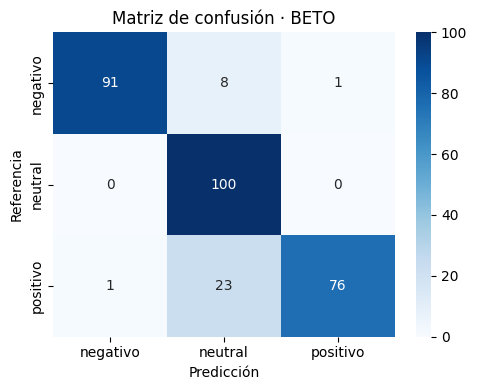

,modelo,accuracy,f1_macro,recall_negativo,latencia_mediana_ms
0,BETO,0.89,0.890825,0.91,17.214424


Evaluando: RoBERTuito


tokenizer_config.json:   0%|          | 0.00/384 [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/167 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/925 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/435M [00:00<?, ?B/s]

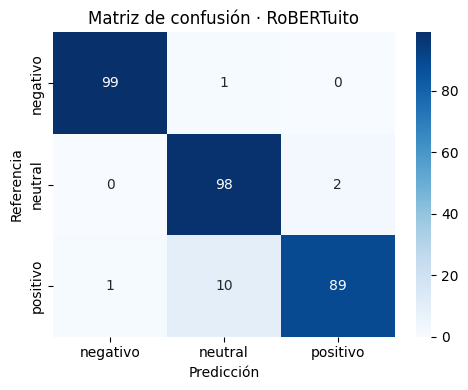

,modelo,accuracy,f1_macro,recall_negativo,latencia_mediana_ms
0,RoBERTuito,0.953333,0.953245,0.99,8.227487


Evaluando: XLM-RoBERTa


config.json:   0%|          | 0.00/841 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/1.11G [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.11G [00:00<?, ?B/s]

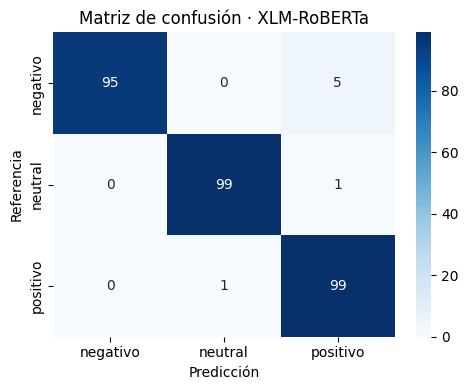

,modelo,accuracy,f1_macro,recall_negativo,latencia_mediana_ms
0,XLM-RoBERTa,0.976667,0.976738,0.95,26.581603


Los tres modelos terminaron. Resultados guardados.


In [8]:
def normalize_label(label):
    mapping={'neg':'negativo','negative':'negativo','negativo':'negativo',
             'neu':'neutral','neutral':'neutral',
             'pos':'positivo','positive':'positivo','positivo':'positivo'}
    key=str(label).strip().lower()
    if key not in mapping:
        raise ValueError(f'Etiqueta desconocida: {label}. Revisa la configuración del checkpoint.')
    return mapping[key]

def infer(texts,tokenizer,model):
    inputs=tokenizer(texts,return_tensors='pt',padding=True,truncation=True,max_length=MAX_LENGTH)
    inputs={k:v.to(DEVICE) for k,v in inputs.items()}
    with torch.inference_mode():
        probabilities=torch.softmax(model(**inputs).logits,dim=-1)
    return probabilities.cpu().numpy()

def evaluate_metrics(y_true,y_pred):
    precision,recall,f1,_=precision_recall_fscore_support(y_true,y_pred,labels=LABELS,average='macro',zero_division=0)
    report=classification_report(y_true,y_pred,labels=LABELS,output_dict=True,zero_division=0)
    return {'accuracy':accuracy_score(y_true,y_pred),'precision_macro':precision,'recall_macro':recall,
            'f1_macro':f1,'recall_negativo':report['negativo']['recall']}, report

texts=df['comentario'].tolist()
y_true=df['sentimiento'].tolist()
benchmark_idx=np.random.default_rng(SEED).choice(len(df),size=30,replace=False)
metrics_rows=[]; predictions=[]; topic_rows=[]; latency_rows=[]
for name,repo in MODELS.items():
    print('Evaluando:',name)
    torch.cuda.empty_cache(); torch.cuda.synchronize()
    loading_start=time.perf_counter()
    tokenizer=AutoTokenizer.from_pretrained(repo,revision=revisions[repo],trust_remote_code=False)
    model=AutoModelForSequenceClassification.from_pretrained(repo,revision=revisions[repo],trust_remote_code=False).float().to(DEVICE)
    model.eval()
    torch.cuda.synchronize()
    load_seconds=time.perf_counter()-loading_start
    class_names=[normalize_label(model.config.id2label[i]) for i in range(model.config.num_labels)]
    assert len(class_names)==3 and set(class_names)==set(LABELS)
    parameters=sum(p.numel() for p in model.parameters())
    parameter_bytes=sum(p.numel()*p.element_size() for p in model.parameters())
    lengths=[len(tokenizer(t,add_special_tokens=True,truncation=False)['input_ids']) for t in texts]
    # Calentamiento para el recorrido por lotes.
    for _ in range(3):
        infer(texts[:BATCH_SIZE],tokenizer,model)
    torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
    start=time.perf_counter()
    probs=np.concatenate([infer(texts[i:i+BATCH_SIZE],tokenizer,model) for i in range(0,len(texts),BATCH_SIZE)])
    torch.cuda.synchronize()
    batch_seconds=time.perf_counter()-start
    peak_gpu_mb=torch.cuda.max_memory_allocated()/1024**2
    pred=[class_names[i] for i in probs.argmax(axis=1)]
    confidence=probs.max(axis=1)
    metrics,report=evaluate_metrics(y_true,pred)
    # Medición individual distinta del rendimiento por lotes.
    for _ in range(5):
        infer([texts[int(benchmark_idx[0])]],tokenizer,model)
    times=[]
    for repetition in range(3):
        for index in benchmark_idx:
            torch.cuda.synchronize(); start=time.perf_counter()
            infer([texts[int(index)]],tokenizer,model)
            torch.cuda.synchronize()
            ms=(time.perf_counter()-start)*1000
            times.append(ms)
            latency_rows.append({'modelo':name,'id':df.iloc[int(index)]['id'],'repeticion':repetition+1,'latencia_ms':ms})
    kept=confidence>=REVIEW_THRESHOLD
    selective_accuracy=accuracy_score(np.array(y_true)[kept],np.array(pred)[kept]) if kept.any() else None
    row={'modelo':name,**metrics,'latencia_mediana_ms':float(np.median(times)),
         'latencia_p95_ms':float(np.percentile(times,95)),'tiempo_lote_s':batch_seconds,
         'comentarios_por_segundo_lote':len(df)/batch_seconds,'carga_y_descarga_s':load_seconds,
         'parametros_millones':parameters/1e6,'parametros_fp32_MB':parameter_bytes/1024**2,
         'gpu_pico_asignado_MB':peak_gpu_mb,'textos_truncados':sum(n>MAX_LENGTH for n in lengths),
         'cobertura_umbral_070':float(kept.mean()),'accuracy_retenidos':selective_accuracy,
         'licencia_metadatos':str(infos[name]['licencia_metadatos'])}
    metrics_rows.append(row)
    (ROOT/'results'/f'metricas_clase_{name}.json').write_text(json.dumps(report,ensure_ascii=False,indent=2),encoding='utf-8')
    for i,record in df.iterrows():
        predictions.append({'modelo':name,**record.to_dict(),'prediccion':pred[i],
                            'score_maximo':float(confidence[i]),'correcto':pred[i]==record['sentimiento'],
                            'revision_humana_sugerida':bool(not kept[i]),
                            **{f'p_{label}':float(probs[i,class_names.index(label)]) for label in LABELS}})
    for topic in sorted(df['tema'].unique()):
        indices=np.flatnonzero(df['tema'].eq(topic).to_numpy())
        partial,_=evaluate_metrics(np.array(y_true)[indices],np.array(pred)[indices])
        topic_rows.append({'modelo':name,'tema':topic,'n':len(indices),**partial})
    fig,ax=plt.subplots(figsize=(5,4))
    sns.heatmap(confusion_matrix(y_true,pred,labels=LABELS),annot=True,fmt='d',cmap='Blues',
                xticklabels=LABELS,yticklabels=LABELS,ax=ax)
    ax.set(xlabel='Predicción',ylabel='Referencia',title=f'Matriz de confusión · {name}')
    fig.tight_layout(); fig.savefig(ROOT/'results'/f'confusion_{name}.png',dpi=180); plt.show(); plt.close(fig)
    display(pd.DataFrame([row])[['modelo','accuracy','f1_macro','recall_negativo','latencia_mediana_ms']])
    del model,tokenizer,probs
    gc.collect(); torch.cuda.empty_cache()

metrics_df=pd.DataFrame(metrics_rows)
pred_df=pd.DataFrame(predictions)
topic_df=pd.DataFrame(topic_rows)
metrics_df.to_csv(ROOT/'results/metricas_comparativas.csv',index=False,encoding='utf-8-sig')
pred_df.to_csv(ROOT/'results/predicciones.csv',index=False,encoding='utf-8-sig')
topic_df.to_csv(ROOT/'results/metricas_por_tema.csv',index=False,encoding='utf-8-sig')
pd.DataFrame(latency_rows).to_csv(ROOT/'results/latencias_individuales.csv',index=False,encoding='utf-8-sig')
errors=pred_df.loc[~pred_df['correcto']].sort_values('score_maximo',ascending=False)
errors.to_csv(ROOT/'results/errores.csv',index=False,encoding='utf-8-sig')
print('Los tres modelos terminaron. Resultados guardados.')


## 8. Comparación, umbral y conclusiones parciales
Revisa especialmente errores de ironía, negación y experiencias mixtas. Una alta exactitud en frases sintéticas explícitas puede sobreestimar el desempeño real. El subconjunto retenido por el umbral es más fácil; su accuracy no reemplaza la accuracy de los 300 textos. Identificar insatisfacción requiere observar además los falsos negativos.

La base de comparación constante predice siempre neutral: sirve para contextualizar las métricas, no como cuarto modelo de Hugging Face.


Baseline constante neutral: {'accuracy': 0.3333333333333333, 'precision_macro': 0.1111111111111111, 'recall_macro': 0.3333333333333333, 'f1_macro': 0.16666666666666666, 'recall_negativo': 0.0}


,modelo,accuracy,precision_macro,recall_macro,f1_macro,recall_negativo,latencia_mediana_ms,latencia_p95_ms,tiempo_lote_s,comentarios_por_segundo_lote,carga_y_descarga_s,parametros_millones,parametros_fp32_MB,gpu_pico_asignado_MB,textos_truncados,cobertura_umbral_070,accuracy_retenidos,licencia_metadatos
0,BETO,0.8900,0.9132,0.8900,0.8908,0.91,17.2144,49.2170,0.4862,617.0134,12.3334,109.8563,419.0684,439.5659,0,0.9800,0.8980,no declarada
1,RoBERTuito,0.9533,0.9557,0.9533,0.9532,0.99,8.2275,14.2196,0.3849,779.3367,5.1374,108.7910,415.0049,435.7261,0,0.9467,0.9859,no declarada
2,XLM-RoBERTa,0.9767,0.9776,0.9767,0.9767,0.95,26.5816,45.0760,0.4548,659.6139,13.4347,278.0460,1060.6611,1086.8408,0,0.9100,0.9890,no declarada


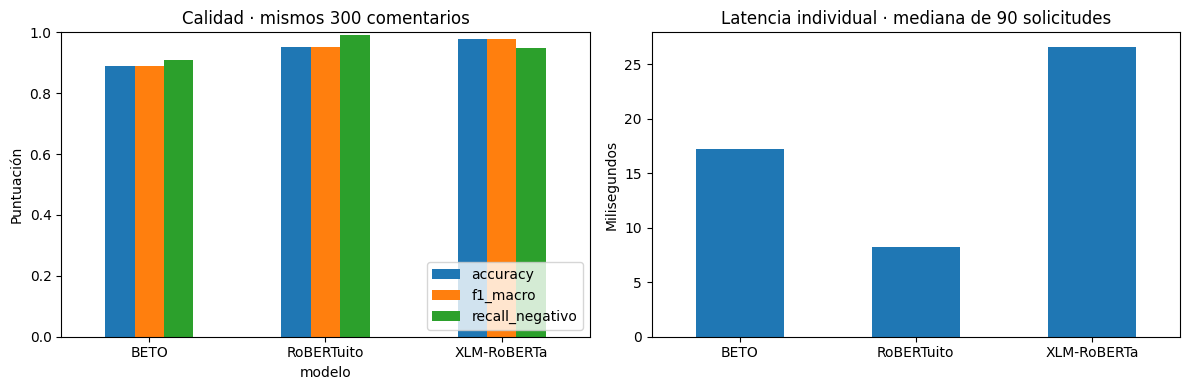

Errores con mayor score (revisar también la etiqueta de referencia):


,modelo,comentario,sentimiento,prediccion,score_maximo
50,BETO,Qué práctica está la función para guardar mis ...,positivo,neutral,0.998438
102,BETO,Registrar la reclamación desde la app fue muy ...,positivo,neutral,0.998376
193,BETO,"Aunque era un servicio nuevo, el pago fue muy ...",positivo,neutral,0.998249
156,BETO,"Aunque el diseño se ve bonito, prefiero que fu...",negativo,neutral,0.998138
89,BETO,"No batallé para consultar el número digital, e...",positivo,neutral,0.998013
17,BETO,"Aunque era mi primera transferencia, el proces...",positivo,neutral,0.997994
155,BETO,No me cobraron por la transferencia y quedé sa...,positivo,neutral,0.997625
172,BETO,Qué seguridad tan práctica: no puedo entrar ni...,negativo,neutral,0.997371
143,BETO,La referencia se leyó correctamente a la prime...,positivo,neutral,0.996319
3,BETO,"Aunque resolvieron el rechazo, fue tan tardado...",negativo,neutral,0.994043


Recomendación exploratoria: XLM-RoBERTa · F1 macro 0.977 · recall negativo 0.950.
Menor mediana de latencia: RoBERTuito (8.23 ms).
La recomendación requiere revisión de errores, licencias y validación con datos independientes antes de uso real.


In [9]:
baseline,_=evaluate_metrics(y_true,['neutral']*len(y_true))
print('Baseline constante neutral:',baseline)
display(metrics_df.round(4))
fig,axes=plt.subplots(1,2,figsize=(12,4))
metrics_df.set_index('modelo')[['accuracy','f1_macro','recall_negativo']].plot.bar(ax=axes[0],ylim=(0,1),rot=0)
axes[0].set(title='Calidad · mismos 300 comentarios',ylabel='Puntuación')
axes[0].legend(loc='lower right')
metrics_df.plot.bar(x='modelo',y='latencia_mediana_ms',ax=axes[1],legend=False,rot=0)
axes[1].set(title='Latencia individual · mediana de 90 solicitudes',ylabel='Milisegundos',xlabel='')
fig.tight_layout(); fig.savefig(ROOT/'results/comparacion.png',dpi=180); plt.show(); plt.close(fig)
print('Errores con mayor score (revisar también la etiqueta de referencia):')
display(errors[['modelo','comentario','sentimiento','prediccion','score_maximo']].head(15))
max_f1=metrics_df['f1_macro'].max()
contenders=metrics_df.loc[metrics_df['f1_macro']>=max_f1-0.01]
winner=contenders.sort_values(['recall_negativo','latencia_mediana_ms','modelo'],ascending=[False,True,True]).iloc[0]
fastest=metrics_df.sort_values('latencia_mediana_ms').iloc[0]
print(f"Recomendación exploratoria: {winner['modelo']} · F1 macro {winner['f1_macro']:.3f} · recall negativo {winner['recall_negativo']:.3f}.")
print(f"Menor mediana de latencia: {fastest['modelo']} ({fastest['latencia_mediana_ms']:.2f} ms).")
print('La recomendación requiere revisión de errores, licencias y validación con datos independientes antes de uso real.')


##9. Conclusión

La evaluación de los tres modelos sobre 300 comentarios bancarios sintéticos mostró diferencias entre calidad de clasificación y velocidad. XLM-RoBERTa obtuvo el mejor desempeño global, con una exactitud de 97.67 % y un F1 macro de 0.977, por lo que fue seleccionado conforme al criterio definido antes de la evaluación. Su latencia mediana fue de 26.58 ms, la mayor de los tres modelos.

RoBERTuito ofreció una alternativa relevante para escenarios donde detectar insatisfacción y responder rápidamente tenga mayor peso: identificó correctamente el 99 % de los comentarios negativos y registró la menor latencia mediana, de 8.23 ms. BETO alcanzó una exactitud de 89 % y presentó más dificultades para reconocer comentarios positivos, clasificando 23 de ellos como neutrales.

La revisión de errores también mostró que un score elevado puede acompañar una clasificación incorrecta. Por ello, el umbral de 0.70 no garantiza aciertos y debe complementarse con revisión humana, especialmente ante ironía, negaciones y experiencias mixtas.

En consecuencia, XLM-RoBERTa es la opción recomendada para continuar la evaluación por su equilibrio entre clases, mientras que RoBERTuito merece consideración si se priorizan rapidez y detección de comentarios negativos. Estos resultados son exploratorios: el uso de datos sintéticos y etiquetas pendientes de revisión independiente limita su aplicación a comentarios reales. Antes de una implementación sería necesario validar con datos representativos, revisar las condiciones de licencia y definir criterios de supervisión humana.
